In [2]:
import pandas as pd            
import numpy as np             
import matplotlib.pyplot as plt  

pd.set_option("display.max_columns", None)   # que no oculte columnas al mostrar tablas
pd.set_option("display.max_colwidth", 60)    # que no recorte textos largos

In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")

In [4]:
print("train:", train.shape)
print("test:", test.shape)
print("sample:", sample.shape)

train: (912, 14)
test: (391, 13)
sample: (391, 2)


In [5]:
train.head()

,id,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,697,705,Asus,Chromebook Flip,2 in 1 Convertible,12.5,Full HD / Touchscreen 1920x1080,Intel Core M M3-6Y30 0.9GHz,4GB,64GB Flash Storage,Intel HD Graphics 515,Chrome OS,1.2kg,669.0
1,435,442,Asus,Rog Strix,Gaming,17.3,Full HD 1920x1080,AMD Ryzen 1600 3.2GHz,8GB,256GB SSD + 1TB HDD,AMD Radeon RX 580,Windows 10,3.2kg,1695.0
2,735,743,Lenovo,V310-15IKB (i7-7500U/4GB/1TB/FHD/W10),Notebook,15.6,Full HD 1920x1080,Intel Core i7 7500U 2.7GHz,4GB,1TB HDD,Intel HD Graphics 620,Windows 10,1.85kg,779.0
3,864,875,Dell,XPS 13,Ultrabook,13.3,Quad HD+ / Touchscreen 3200x1800,Intel Core i7 7660U 2.5GHz,16GB,512GB SSD,Intel Iris Plus Graphics 640,Windows 10,1.29kg,2240.0
4,1176,1194,Lenovo,B51-80 (i7-6500U/4GB/1008GB/FHD/W7),Notebook,15.6,Full HD 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,1.0TB Hybrid,Intel HD Graphics 520,Windows 7,2.32kg,825.0


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                912 non-null    int64  
 1   laptop_ID         912 non-null    int64  
 2   Company           912 non-null    str    
 3   Product           912 non-null    str    
 4   TypeName          912 non-null    str    
 5   Inches            912 non-null    float64
 6   ScreenResolution  912 non-null    str    
 7   Cpu               912 non-null    str    
 8   Ram               912 non-null    str    
 9   Memory            912 non-null    str    
 10  Gpu               912 non-null    str    
 11  OpSys             912 non-null    str    
 12  Weight            912 non-null    str    
 13  Price_euros       912 non-null    float64
dtypes: float64(2), int64(2), str(10)
memory usage: 99.9 KB


In [7]:
train["Price_euros"].describe()

count     912.00000
mean     1126.92034
std       696.08887
min       174.00000
25%       589.00000
50%       952.00000
75%      1499.00000
max      4899.00000
Name: Price_euros, dtype: float64

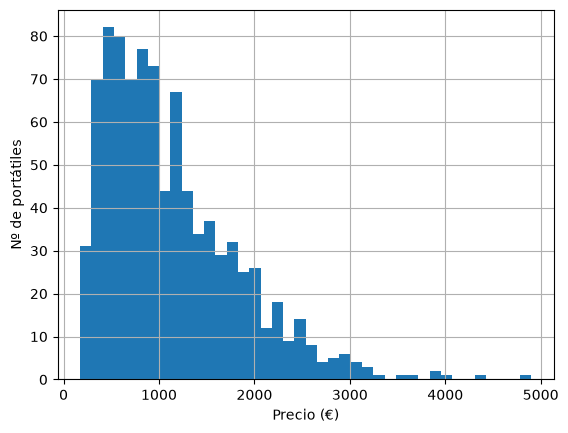

In [8]:
# cómo se reparte el precio

train["Price_euros"].hist(bins=40)
plt.xlabel("Precio (€)")
plt.ylabel("Nº de portátiles")
plt.show()

In [9]:
# primer modelo, predecir el mismo precio para todos los portátiles.

precio = train["Price_euros"]

pred_mediana = precio.median()
pred_media = precio.mean()

mae_mediana = (precio - pred_mediana).abs().mean()
mae_media = (precio - pred_media).abs().mean()

print(f"Siempre la mediana ({pred_mediana:.0f} €): MAE = {mae_mediana:.1f} €")
print(f"Siempre la media   ({pred_media:.0f} €): MAE = {mae_media:.1f} €")

Siempre la mediana (952 €): MAE = 530.2 €
Siempre la media   (1127 €): MAE = 544.7 €


In [10]:
# otro modelo, la mediana según el tipo de portátil

mediana_por_tipo = train.groupby("TypeName")["Price_euros"].transform("median")
mae_tipo = (precio - mediana_por_tipo).abs().mean()
print(f"Mediana por TypeName: MAE = {mae_tipo:.1f} €")

Mediana por TypeName: MAE = 393.5 €


In [11]:
# Comparar el precio medio y la mediana según el tipo de portátil y la marca

print(train.groupby("TypeName")["Price_euros"].agg(["count", "median", "mean"]).round(0))
print()
print(train.groupby("Company")["Price_euros"].agg(["count", "median", "mean"]).round(0).sort_values("median", ascending=False))

                    count  median    mean
TypeName                                 
2 in 1 Convertible     84  1239.0  1274.0
Gaming                143  1499.0  1743.0
Netbook                17   297.0   631.0
Notebook              516   690.0   788.0
Ultrabook             130  1514.0  1560.0
Workstation            22  2100.0  2331.0

           count  median    mean
Company                         
Razer          4  2749.0  2699.0
LG             1  2299.0  2299.0
Google         1  2199.0  2199.0
MSI           36  1855.0  1834.0
Microsoft      4  1833.0  1836.0
Samsung        5  1649.0  1403.0
Huawei         2  1424.0  1424.0
Apple         17  1419.0  1570.0
Toshiba       37  1210.0  1274.0
Xiaomi         2  1200.0  1200.0
Asus         110  1044.0  1137.0
HP           197  1011.0  1119.0
Dell         218   966.0  1176.0
Lenovo       193   849.0  1046.0
Fujitsu        1   739.0   739.0
Acer          76   546.0   607.0
Chuwi          1   449.0   449.0
Mediacom       6   282.0   304.0
Ver

In [12]:
# qué columnas tienen pocas categorías (TypeName, OpSys) y cuáles tienen muchísimas (Product, Cpu).

columnas_texto = ["Company", "Product", "TypeName", "ScreenResolution", "Cpu", "Ram", "Memory", "Gpu", "OpSys", "Weight"]
train[columnas_texto].nunique().sort_values()

TypeName              6
Ram                   9
OpSys                 9
Company              19
Memory               36
ScreenResolution     37
Gpu                  94
Cpu                 102
Weight              164
Product             475
dtype: int64

In [13]:
# convertir texto en número, haciendo copa del data

df = train.copy()

# "8GB" -> 8
df["Ram_gb"] = df["Ram"].str.extract(r"(\d+)")[0].astype(int)

# "1.2kg" -> 1.2
df["Weight_kg"] = df["Weight"].str.extract(r"([\d.]+)")[0].astype(float)

df[["Ram", "Ram_gb", "Weight", "Weight_kg"]].head()

,Ram,Ram_gb,Weight,Weight_kg
0,4GB,4,1.2kg,1.20
1,8GB,8,3.2kg,3.20
2,4GB,4,1.85kg,1.85
3,16GB,16,1.29kg,1.29
4,4GB,4,2.32kg,2.32


In [14]:
# se relaciona con el precio?

df[["Ram_gb", "Weight_kg", "Inches", "Price_euros"]].corr()["Price_euros"].round(2)

Ram_gb         0.73
Weight_kg      0.21
Inches         0.07
Price_euros    1.00
Name: Price_euros, dtype: float64

In [15]:
train["Memory"].value_counts()

Memory
256GB SSD                        284
1TB HDD                          173
500GB HDD                         85
512GB SSD                         80
128GB SSD +  1TB HDD              65
128GB SSD                         53
256GB SSD +  1TB HDD              50
32GB Flash Storage                27
512GB SSD +  1TB HDD              11
64GB Flash Storage                10
1TB SSD                           10
2TB HDD                            9
256GB SSD +  2TB HDD               9
1.0TB Hybrid                       6
32GB SSD                           6
16GB Flash Storage                 5
256GB Flash Storage                4
512GB SSD +  2TB HDD               3
128GB Flash Storage                2
512GB Flash Storage                2
256GB SSD +  256GB SSD             2
256GB SSD +  500GB HDD             2
180GB SSD                          1
512GB SSD +  256GB SSD             1
508GB Hybrid                       1
128GB HDD                          1
256GB SSD +  1.0TB Hybrid      

In [16]:
# separar memoory en cuatro columnas numéricas, una por tipo, todas en GB (1 TB = 1024 GB):

import re

def parsear_memoria(texto):
    ssd = hdd = hibrido = flash = 0.0
    for parte in texto.split("+"):                 # dos discos vienen separados por "+"
        m = re.search(r"([\d.]+)\s*(TB|GB)", parte)
        if m is None:
            continue
        tam = float(m.group(1)) * (1024 if m.group(2) == "TB" else 1)
        if "SSD" in parte:
            ssd += tam
        elif "HDD" in parte:
            hdd += tam
        elif "Hybrid" in parte:
            hibrido += tam
        elif "Flash" in parte:
            flash += tam
    return pd.Series([ssd, hdd, hibrido, flash])

df[["SSD_gb", "HDD_gb", "Hybrid_gb", "Flash_gb"]] = df["Memory"].apply(parsear_memoria)
df[["Memory", "SSD_gb", "HDD_gb", "Hybrid_gb", "Flash_gb"]].head(8)

,Memory,SSD_gb,HDD_gb,Hybrid_gb,Flash_gb
0,64GB Flash Storage,0.0,0.0,0.0,64.0
1,256GB SSD + 1TB HDD,256.0,1024.0,0.0,0.0
2,1TB HDD,0.0,1024.0,0.0,0.0
3,512GB SSD,512.0,0.0,0.0,0.0
4,1.0TB Hybrid,0.0,0.0,1024.0,0.0
5,32GB SSD,32.0,0.0,0.0,0.0
6,500GB HDD,0.0,500.0,0.0,0.0
7,256GB SSD + 1TB HDD,256.0,1024.0,0.0,0.0


In [17]:
df["tiene_ssd"] = (df["SSD_gb"] > 0).astype(int)
df.groupby("tiene_ssd")["Price_euros"].agg(["count", "median"])

,count,median
tiene_ssd,,
0,328,561.500
1,584,1279.365


In [18]:
# qué hay en cpu

df["Cpu"].value_counts().head(15)

Cpu
Intel Core i5 7200U 2.5GHz              143
Intel Core i7 7700HQ 2.8GHz             107
Intel Core i7 7500U 2.7GHz               87
Intel Core i3 6006U 2GHz                 51
Intel Core i7 8550U 1.8GHz               46
Intel Core i5 8250U 1.6GHz               45
Intel Core i5 6200U 2.3GHz               43
Intel Core i7 6500U 2.5GHz               36
Intel Core i3 7100U 2.4GHz               28
Intel Core i7 6700HQ 2.6GHz              27
Intel Core i5 7300HQ 2.5GHz              21
Intel Celeron Dual Core N3060 1.6GHz     20
Intel Celeron Dual Core N3350 1.1GHz     19
Intel Core i3 6006U 2.0GHz               13
Intel Core i7 6600U 2.6GHz               12
Name: count, dtype: int64

In [19]:
# extraer tres cosas: la marca (Intel/AMD), la familia (i3, i5, i7...) y los GHz.

df["Cpu_ghz"] = df["Cpu"].str.extract(r"(\d+(?:\.\d+)?)\s*GHz")[0].astype(float)
df["Cpu_brand"] = df["Cpu"].str.split().str[0]

def familia_cpu(texto):
    t = texto.lower()
    for clave, nombre in [("core i9", "i9"), ("core i7", "i7"), ("core i5", "i5"), ("core i3", "i3"),
                          ("core m", "core_m"), ("xeon", "xeon"), ("ryzen", "ryzen"),
                          ("celeron", "celeron"), ("pentium", "pentium"), ("atom", "atom")]:
        if clave in t:
            return nombre
    return "otro"

df["Cpu_family"] = df["Cpu"].apply(familia_cpu)
df[["Cpu", "Cpu_brand", "Cpu_family", "Cpu_ghz"]].head(8)

,Cpu,Cpu_brand,Cpu_family,Cpu_ghz
0,Intel Core M M3-6Y30 0.9GHz,Intel,core_m,0.9
1,AMD Ryzen 1600 3.2GHz,AMD,ryzen,3.2
2,Intel Core i7 7500U 2.7GHz,Intel,i7,2.7
3,Intel Core i7 7660U 2.5GHz,Intel,i7,2.5
4,Intel Core i7 6500U 2.5GHz,Intel,i7,2.5
5,Intel Celeron Quad Core N3450 1.1GHz,Intel,celeron,1.1
6,Intel Pentium Quad Core N4200 1.1GHz,Intel,pentium,1.1
7,Intel Core i7 7700HQ 2.8GHz,Intel,i7,2.8


In [20]:
# ordenar precio por familia

df.groupby("Cpu_family")["Price_euros"].agg(["count", "median"]).sort_values("median")

,count,median
Cpu_family,,
atom,7,265.00
celeron,59,299.00
pentium,19,398.99
otro,43,449.00
i3,104,498.95
i5,295,949.00
core_m,12,1270.70
i7,366,1496.50
ryzen,3,1695.00


In [21]:
# qué hay en otro?

df[df["Cpu_family"] == "otro"]["Cpu"].value_counts().head(10)

Cpu
AMD A9-Series 9420 3GHz         10
AMD A12-Series 9720P 3.6GHz      5
AMD A8-Series 7410 2.2GHz        4
AMD A6-Series 9220 2.5GHz        3
AMD A9-Series A9-9420 3GHz       2
AMD A9-Series 9410 2.9GHz        2
AMD A6-Series A6-9220 2.5GHz     2
AMD E-Series 7110 1.8GHz         2
AMD A12-Series 9720P 2.7GHz      1
AMD E-Series 9000e 1.5GHz        1
Name: count, dtype: int64

In [22]:
# extraer sufijo y generación

# modelo = la palabra justo antes de "GHz", p. ej. "7200U"
modelo = df["Cpu"].str.extract(r"(\S+)\s+\d+(?:\.\d+)?\s*GHz")[0]

df["Cpu_suffix"] = modelo.str.extract(r"\d+([A-Za-z]+)$")[0].fillna("none").str.upper()
df["Cpu_gen"] = modelo.str.extract(r"(\d{4,5})")[0].str[:-3].astype(float)   # 7200U -> 7 ; 10510U -> 10

# la "generación" solo tiene sentido para los Core i3/i5/i7/i9
df.loc[~df["Cpu_family"].isin(["i3", "i5", "i7", "i9"]), "Cpu_gen"] = np.nan

df[["Cpu", "Cpu_family", "Cpu_suffix", "Cpu_gen"]].head(8)

,Cpu,Cpu_family,Cpu_suffix,Cpu_gen
0,Intel Core M M3-6Y30 0.9GHz,core_m,NONE,NaN
1,AMD Ryzen 1600 3.2GHz,ryzen,NONE,NaN
2,Intel Core i7 7500U 2.7GHz,i7,U,7.0
3,Intel Core i7 7660U 2.5GHz,i7,U,7.0
4,Intel Core i7 6500U 2.5GHz,i7,U,6.0
5,Intel Celeron Quad Core N3450 1.1GHz,celeron,NONE,NaN
6,Intel Pentium Quad Core N4200 1.1GHz,pentium,NONE,NaN
7,Intel Core i7 7700HQ 2.8GHz,i7,HQ,7.0


In [23]:
# comprobación solo i7

df[df["Cpu_family"] == "i7"].groupby("Cpu_suffix")["Price_euros"].agg(["count", "median"]).sort_values("median")

,count,median
Cpu_suffix,,
U,201,1299.00
HQ,145,1738.27
NONE,7,2139.97
HK,13,2749.99


In [24]:
def preparar(d):
    d = d.copy()
    d["Ram_gb"] = d["Ram"].str.extract(r"(\d+)")[0].astype(int)
    d["Weight_kg"] = d["Weight"].str.extract(r"([\d.]+)")[0].astype(float)
    d[["SSD_gb", "HDD_gb", "Hybrid_gb", "Flash_gb"]] = d["Memory"].apply(parsear_memoria)

    d["Cpu_ghz"] = d["Cpu"].str.extract(r"(\d+(?:\.\d+)?)\s*GHz")[0].astype(float)
    d["Cpu_family"] = d["Cpu"].apply(familia_cpu)
    mod = d["Cpu"].str.extract(r"(\S+)\s+\d+(?:\.\d+)?\s*GHz")[0]
    d["Cpu_suffix"] = mod.str.extract(r"\d+([A-Za-z]+)\d*$")[0].fillna("none").str.upper()
    d["Cpu_gen"] = mod.str.extract(r"(\d{4,5})")[0].str[:-3].astype(float)
    d.loc[~d["Cpu_family"].isin(["i3", "i5", "i7", "i9"]), "Cpu_gen"] = np.nan
    d["Cpu_gen"] = d["Cpu_gen"].fillna(0)
    return d

num = ["Inches", "Ram_gb", "Weight_kg", "SSD_gb", "HDD_gb", "Hybrid_gb", "Flash_gb", "Cpu_ghz", "Cpu_gen"]
cat = ["Company", "TypeName", "OpSys", "Cpu_family", "Cpu_suffix"]

train_p = preparar(train)
X = train_p[num + cat]
y = train["Price_euros"]

# Celda 2: modelo + validación cruzada

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

# las columnas de texto-categoría se convierten en 0/1 (una columna por categoría)
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat)],
                         remainder="passthrough")

rf_model = Pipeline([("prep", prep),
                     ("rf", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_model, X, y, cv=kf, scoring="neg_mean_absolute_error")

print("MAE por partición:", (-scores).round(1))
print("MAE medio:", (-scores).mean().round(1), "€")

MAE por partición: [190.9 195.5 214.7 193.9 198.4]
MAE medio: 198.7 €


In [25]:
# entrenar con todo train y generar el archivo para Kaggle

rf_model.fit(X, y)

test_p = preparar(test)                      # mismas transformaciones que en train
pred = rf_model.predict(test_p[num + cat])

sub = pd.DataFrame({"id": test["id"], "Price_euros": pred})
sub.to_csv("submission.csv", index=False)
sub.head()

,id,Price_euros
0,824,1605.166200
1,101,358.861794
2,1157,1822.857833
3,940,1245.380833
4,853,1572.577633


In [26]:
# Prueba A: mismo modelo, pero prediciendo el logaritmo del precio

from sklearn.compose import TransformedTargetRegressor

rf_log = TransformedTargetRegressor(regressor=rf_model, func=np.log1p, inverse_func=np.expm1)
scores = cross_val_score(rf_log, X, y, cv=kf, scoring="neg_mean_absolute_error")
print("MAE medio (log):", (-scores).mean().round(1), "€")

MAE medio (log): 200.8 €


In [27]:
# Modelo que minimiza el MAE directamente

from sklearn.ensemble import HistGradientBoostingRegressor

prep_d = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
                           remainder="passthrough")
hgb = Pipeline([("prep", prep_d),
                ("m", HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05,
                                                    max_iter=300, max_leaf_nodes=15,
                                                    min_samples_leaf=5, random_state=42))])

scores = cross_val_score(hgb, X, y, cv=kf, scoring="neg_mean_absolute_error")
print("MAE medio (HGB):", (-scores).mean().round(1), "€")

MAE medio (HGB): 194.6 €


In [28]:
# La tarjeta gráfica es justo lo que más separa los precios altos, y los portátiles caros son donde se concentra el error

train["Gpu"].value_counts().head(15)

Gpu
Intel HD Graphics 620         191
Intel HD Graphics 520         132
Intel UHD Graphics 620         47
Nvidia GeForce GTX 1050        40
Nvidia GeForce GTX 1060        39
Nvidia GeForce 940MX           31
Intel HD Graphics 500          28
AMD Radeon 530                 27
Intel HD Graphics 400          25
Nvidia GeForce GTX 1070        24
Nvidia GeForce GTX 1050 Ti     23
AMD Radeon R5 M430             19
Intel HD Graphics              16
AMD Radeon 520                 13
Nvidia GeForce 930MX           13
Name: count, dtype: int64

In [29]:
# Crear una nueva columna

def serie_gpu(texto):
    t = texto.lower()
    for clave, nombre in [("gtx", "gtx"), ("quadro", "quadro"), ("firepro", "firepro"),
                          ("radeon pro", "radeon_pro"), ("radeon rx", "radeon_rx"),
                          ("geforce", "geforce"), ("radeon", "radeon"), ("iris", "iris"),
                          ("uhd", "uhd"), ("hd graphics", "hd"), ("mali", "mali"),
                          ("nvidia", "nvidia_otro")]:
        if clave in t:
            return nombre
    return "otro"

def preparar2(d):
    d = preparar(d)                                   # todo lo anterior
    d["Gpu_brand"] = d["Gpu"].str.split().str[0]
    d["Gpu_series"] = d["Gpu"].apply(serie_gpu)
    d["Gpu_num"] = d["Gpu"].str.extract(r"(\d{3,4})")[0].astype(float).fillna(0)
    return d

train_p2 = preparar2(train)
print(train_p2["Gpu_series"].value_counts())
train_p2.groupby("Gpu_brand")["Price_euros"].agg(["count", "median"]).sort_values("median")

Gpu_series
hd            437
gtx           168
radeon        117
geforce        90
uhd            47
quadro         24
iris           13
radeon_rx       8
firepro         4
otro            2
radeon_pro      2
Name: count, dtype: int64


,count,median
Gpu_brand,,
AMD,132,649.50
Intel,498,898.97
Nvidia,282,1268.00


In [30]:
num2 = num + ["Gpu_num"]
cat2 = cat + ["Gpu_brand", "Gpu_series"]
X2 = train_p2[num2 + cat2]

def evaluar(modelo, X):
    s = cross_val_score(modelo, X, y, cv=kf, scoring="neg_mean_absolute_error")
    return (-s).mean().round(1)

rf2 = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat2)], remainder="passthrough")),
                ("rf", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])

hgb2 = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat2)], remainder="passthrough")),
                 ("m", HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=300,
                                                     max_leaf_nodes=15, min_samples_leaf=5, random_state=42))])

print("RF  con Gpu:", evaluar(rf2, X2), "€  (antes ≈ 198,7)")
print("HGB con Gpu:", evaluar(hgb2, X2), "€  (antes 194,6)")

RF  con Gpu: 184.7 €  (antes ≈ 198,7)
HGB con Gpu: 178.9 €  (antes 194,6)


In [31]:
def preparar3(d):
    d = preparar2(d)                                   # todo lo anterior + Gpu
    res = d["ScreenResolution"]
    wh = res.str.extract(r"(\d{3,4})\s*x\s*(\d{3,4})").astype(float)
    d["Pixels_mp"] = wh[0] * wh[1] / 1e6               # megapíxeles
    d["Touch"] = res.str.contains("Touchscreen").astype(int)
    d["IPS"] = res.str.contains("IPS").astype(int)
    return d

train_p3 = preparar3(train)
num3 = num2 + ["Pixels_mp", "Touch", "IPS"]
cat3 = cat2
X3 = train_p3[num3 + cat3]

print("RF  con Gpu + pantalla:", evaluar(rf2, X3), "€  (antes 184,7)")
print("HGB con Gpu + pantalla:", evaluar(hgb2, X3), "€  (antes 178,9)")

RF  con Gpu + pantalla: 178.0 €  (antes 184,7)
HGB con Gpu + pantalla: 176.5 €  (antes 178,9)


In [32]:
from sklearn.model_selection import cross_val_predict

oof_rf = cross_val_predict(rf2, X3, y, cv=kf)
oof_hgb = cross_val_predict(hgb2, X3, y, cv=kf)

mae = lambda p: np.abs(p - y).mean().round(1)

print("RF solo :", mae(oof_rf))
print("HGB solo:", mae(oof_hgb))
for w in [0.3, 0.5, 0.7]:
    print(f"Mezcla con {w:.0%} de HGB:", mae(w * oof_hgb + (1 - w) * oof_rf))

RF solo : 178.0
HGB solo: 176.5
Mezcla con 30% de HGB: 173.8
Mezcla con 50% de HGB: 172.8
Mezcla con 70% de HGB: 173.3


In [33]:
w = 0.5   # cambiarlo por el que mejor te salga

rf2.fit(X3, y)
hgb2.fit(X3, y)
X_test3 = preparar3(test)[num3 + cat3]

pred = w * hgb2.predict(X_test3) + (1 - w) * rf2.predict(X_test3)
sub = pd.DataFrame({"id": test["id"], "Price_euros": pred})
sub.to_csv("submission_mezcla_rf_hgb.csv", index=False)
sub.head()

,id,Price_euros
0,824,1564.896026
1,101,367.941482
2,1157,1767.960319
3,940,1182.624382
4,853,1381.745009


In [34]:
# Product 

def preparar4(d):
    d = preparar3(d)
    p = d["Product"].str.strip()
    d["Product_line"] = p.str.split().str[0]
    d["is_gaming"] = p.str.contains(r"Gaming|Predator|Legion|ROG|Alienware|Omen|Nitro|TUF|Strix|Helios|Zephyrus|Rog",
                                    case=False, regex=True).astype(int)
    d["is_workstation"] = p.str.contains(r"Precision|ZBook|Zbook|Workstation|Thinkpad P|ThinkPad P",
                                         case=False, regex=True).astype(int)
    return d

train_p4 = preparar4(train)
num4 = num3 + ["is_gaming", "is_workstation"]
cat4 = cat3 + ["Product_line"]
X4 = train_p4[num4 + cat4]

def modelos(cat_list):
    rf = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_list)], remainder="passthrough")),
                   ("rf", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])
    hgb = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_list)], remainder="passthrough")),
                    ("m", HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=300,
                                                        max_leaf_nodes=15, min_samples_leaf=5, random_state=42))])
    return rf, hgb

rf4, hgb4 = modelos(cat4)
oof_rf4 = cross_val_predict(rf4, X4, y, cv=kf)
oof_hgb4 = cross_val_predict(hgb4, X4, y, cv=kf)
print("RF  :", mae(oof_rf4), "(antes 178,0)")
print("HGB :", mae(oof_hgb4), "(antes 176,5)")
print("Mezcla 50/50:", mae(0.5 * oof_rf4 + 0.5 * oof_hgb4), "(antes 172,8)")

RF  : 174.1 (antes 178,0)
HGB : 167.7 (antes 176,5)
Mezcla 50/50: 165.8 (antes 172,8)


In [35]:
rf4.fit(X4, y)
hgb4.fit(X4, y)
X_test4 = preparar4(test)[num4 + cat4]

pred = 0.5 * hgb4.predict(X_test4) + 0.5 * rf4.predict(X_test4)
sub = pd.DataFrame({"id": test["id"], "Price_euros": pred})
sub.to_csv("submission_mezcla_product_cv165.csv", index=False)
sub.head()

,id,Price_euros
0,824,1529.024162
1,101,380.436901
2,1157,1922.724324
3,940,1140.330003
4,853,1578.877104
